In [1]:
import pandas as pd
import numpy as np
import joblib
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, roc_auc_score

In [2]:
df = pd.read_csv("../data/loan_approval_dataset.csv")

In [3]:
df.shape

(4269, 13)

In [4]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [5]:
df.columns

Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='str')

In [6]:
df.columns = df.columns.str.strip()
df.columns

Index(['loan_id', 'no_of_dependents', 'education', 'self_employed',
       'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
       'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value', 'loan_status'],
      dtype='str')

In [7]:
for col in ["education", "self_employed", "loan_status"]:
    df[col] = df[col].astype(str).str.strip()

In [8]:
df.isna().sum()

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

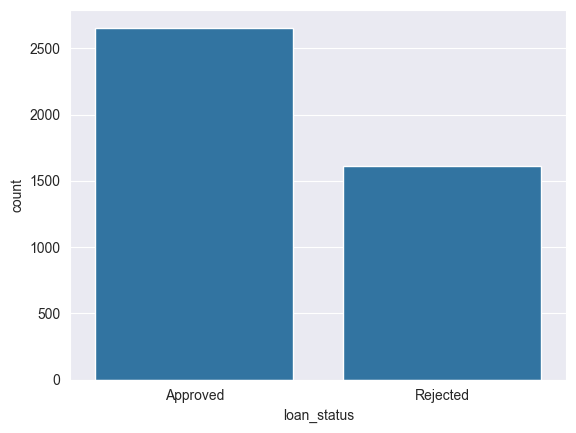

In [9]:
sns.countplot(df, x="loan_status")

<Axes: xlabel='loan_status', ylabel='cibil_score'>

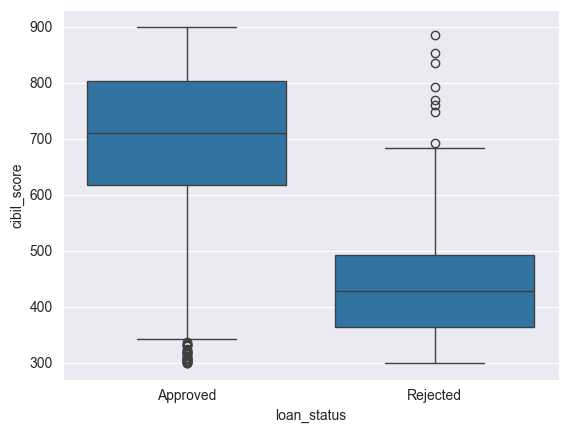

In [10]:
sns.boxplot(data=df, x="loan_status", y="cibil_score")

In [11]:
df = df.drop(columns=["loan_id"])
df["loan_status"] = df["loan_status"].map({"Approved": 1, "Rejected": 0})
df["loan_status"]

0       1
1       0
2       0
3       0
4       0
       ..
4264    0
4265    1
4266    0
4267    1
4268    1
Name: loan_status, Length: 4269, dtype: int64

In [12]:
X = df.drop(columns=["loan_status"])
y = df["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [13]:
cat_cols = ["education", "self_employed"]

model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    cat_features=cat_cols,  
    random_seed=42,
    verbose=100, 
)

model.fit(X_train, y_train, eval_set=(X_test, y_test), early_stopping_rounds=50)

preds_class = model.predict(X_test)
preds_proba = model.predict_proba(X_test)[:, 1]

0:	learn: 0.5813897	test: 0.5777742	best: 0.5777742 (0)	total: 59.6ms	remaining: 29.7s
100:	learn: 0.0356513	test: 0.0505412	best: 0.0505412 (100)	total: 204ms	remaining: 807ms
200:	learn: 0.0191188	test: 0.0459230	best: 0.0459205 (199)	total: 339ms	remaining: 504ms
300:	learn: 0.0114730	test: 0.0440923	best: 0.0440923 (300)	total: 467ms	remaining: 309ms
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.04342107417
bestIteration = 324

Shrink model to first 325 iterations.


In [14]:
roc_auc_score(y_test, preds_proba)

0.9988747208666398

In [15]:
print(classification_report(y_test, preds_class))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       323
           1       0.98      0.99      0.99       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



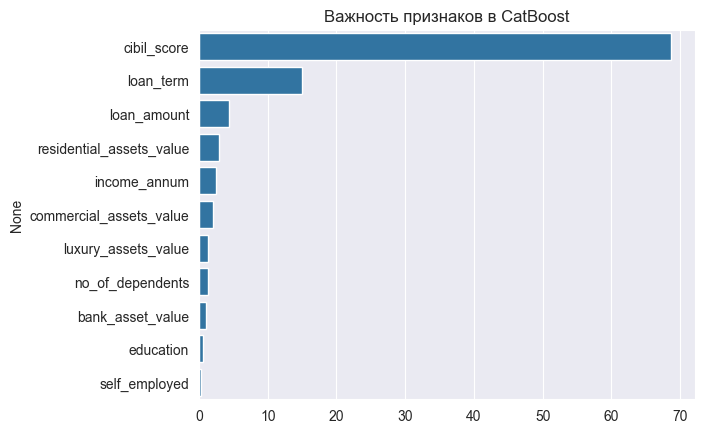

In [16]:
feature_importances = pd.Series(
    model.get_feature_importance(), index=X_train.columns
).sort_values(ascending=False)
sns.barplot(x=feature_importances.values, y=feature_importances.index)
plt.title("Важность признаков в CatBoost")
plt.show()

In [17]:
joblib.dump(model, "../models/catboost_loan_model.joblib")

['../models/catboost_loan_model.joblib']